# Descriptive Analysis (training set only)

**Group:** Nathaniel Horton, Macy Moore, Ava Lawless

**Course:** DS-4021

This notebook explores the training set (`Data/X_train.csv`, `Data/y_train.csv`, 80% of the data) and gives summary statistics and visualizations. The reporting set is notably not used here as it is to remain untouched until the final evaluation.

## Setup and data loading

When this notebook runs on Google Colab, the first cell clones the group repo so the data files are actually available. On a local machine, it does nothing.

In [1]:
import os
import subprocess
import sys

REPO_URL = "https://github.com/macyrm/ds4021_finalproject.git"
REPO_DIR = "ds4021_finalproject"

# clone the repo for the working directory
if "google.colab" in sys.modules and not os.path.exists("Data"):
    if not os.path.exists(REPO_DIR):
        subprocess.run(["git", "clone", REPO_URL], check=True)
    os.chdir(REPO_DIR)

print("Working directory:", os.getcwd())

Working directory: /content/ds4021_finalproject


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# consistent reproducibility
SEED = 42
np.random.seed(SEED)

# style choices
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [3]:
# read in train data files
X_train = pd.read_csv("Data/X_train.csv")
y_train = pd.read_csv("Data/y_train.csv")

# 1 dataframe with features and target, just for exploration
df = X_train.copy()
df["Diabetes"] = y_train["Diabetes_binary"].astype(int)

print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
df.head()

Shape: (202944, 22)
Missing values: 0


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes
0,0.0,0.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,1.0,2.0,4.0,5.0,0
1,1.0,0.0,1.0,23.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,1.0,13.0,4.0,7.0,0
2,1.0,1.0,1.0,29.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,9.0,6.0,8.0,0
3,1.0,1.0,1.0,39.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4.0,0.0,0.0,0.0,1.0,7.0,4.0,7.0,0
4,0.0,1.0,1.0,16.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,7.0,5.0,1.0,0


### Feature groups and labels

The dataset has 3 kinds of features (continuous, ordinal, binary). Age, education, and income are stored as codes, so the labels below make plots readable (code use the BRFSS 2015 codebook).

In [4]:
continuous = ["BMI", "MentHlth", "PhysHlth"]
ordinal = ["GenHlth", "Age", "Education", "Income"]
binary = [c for c in X_train.columns if c not in continuous + ordinal]

age_labels = {1: "18-24", 2: "25-29", 3: "30-34", 4: "35-39", 5: "40-44", 6: "45-49",
              7: "50-54", 8: "55-59", 9: "60-64", 10: "65-69", 11: "70-74", 12: "75-79", 13: "80+"}
education_labels = {1: "Never attended", 2: "Grades 1-8", 3: "Grades 9-11",
                    4: "High school grad", 5: "Some college", 6: "College grad"}
income_labels = {1: "<$10k", 2: "$10-15k", 3: "$15-20k", 4: "$20-25k",
                 5: "$25-35k", 6: "$35-50k", 7: "$50-75k", 8: "$75k+"}
genhlth_labels = {1: "Excellent", 2: "Very good", 3: "Good", 4: "Fair", 5: "Poor"}

print("Continuous:", continuous)
print("Ordinal:", ordinal)
print("Binary:", binary)

Continuous: ['BMI', 'MentHlth', 'PhysHlth']
Ordinal: ['GenHlth', 'Age', 'Education', 'Income']
Binary: ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']


## Target distribution

,Count,Percent
Diabetes,,
No diabetes,174667,86.1
Diabetes,28277,13.9


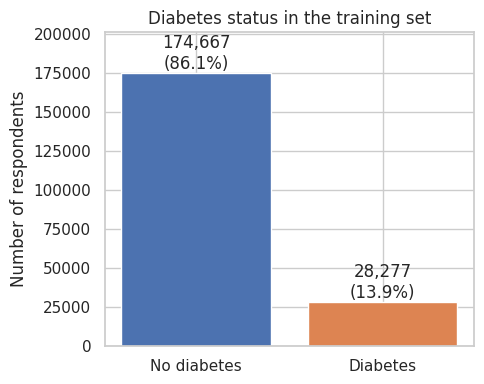

In [5]:
counts = df["Diabetes"].value_counts().sort_index()
target_table = pd.DataFrame({
    "Count": counts,
    "Percent": (counts / len(df) * 100).round(1),
}).rename(index={0: "No diabetes", 1: "Diabetes"})
display(target_table)

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(target_table.index, target_table["Count"], color=["#4C72B0", "#DD8452"])
ax.set_title("Diabetes status in the training set")
ax.set_ylabel("Number of respondents")
for i, (n, p) in enumerate(zip(target_table["Count"], target_table["Percent"])):
    ax.text(i, n, f"{n:,}\n({p}%)", ha="center", va="bottom")
ax.set_ylim(0, target_table["Count"].max() * 1.15)
plt.tight_layout()
plt.show()

The training set is imbalanced with 174,667 (86.1%) respondents not having diabetes, and 28,277 (13.9%) do have diabetes. This is a ratio of about 6 to 1. This matters for modeling because a class imbalance like this means that a model that just guesses no diabetes every time would get to 86% accuracy and not identify a single person with diabetes. Accuracy alone is therefore going to be a misleading metric here when used alone, so we will instead compare models with metrics that actually reflect how well they detect the minority class. Some of these include ROC-AUC, recall, precision, F1 score, and overall analysis of the confusion matrix itself. Whenever possible, we'll also account for the class imbalance when training the models with methods like class weighting and use stratified cross-validation so each fold keeps approximately the same 86/14 split.

## Summary statistics

In [6]:
# Continuous features: mean, SD, range
df[continuous].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
BMI,202944.0,28.38,6.60,12.0,24.0,27.0,31.0,98.0
MentHlth,202944.0,3.19,7.42,0.0,0.0,0.0,2.0,30.0
PhysHlth,202944.0,4.25,8.73,0.0,0.0,0.0,3.0,30.0


In [7]:
# Binary features: proportion of respondents coded 1 ("yes"; for Sex, 1 = male)
(df[binary].mean() * 100).round(1).sort_values(ascending=False).to_frame("% yes")

,% yes
CholCheck,96.2
AnyHealthcare,95.1
Veggies,81.1
PhysActivity,75.7
Fruits,63.4
Smoker,44.3
Sex,44.1
HighBP,42.9
HighChol,42.4
DiffWalk,16.8


In [8]:
# Ordinal features: percent of respondents at each level
label_maps = {"GenHlth": genhlth_labels, "Age": age_labels, "Education": education_labels, "Income": income_labels}
for col, labels in label_maps.items():
    percent = (df[col].map(labels).value_counts(normalize = True).reindex(labels.values()).mul(100).round(1))
    display(percent.to_frame(f'{col} (% of respondents)'))

,GenHlth (% of respondents)
GenHlth,
Excellent,17.9
Very good,35.1
Good,29.9
Fair,12.5
Poor,4.7


,Age (% of respondents)
Age,
18-24,2.2
25-29,3.0
30-34,4.4
35-39,5.4
40-44,6.4
45-49,7.9
50-54,10.4
55-59,12.2
60-64,13.1


,Education (% of respondents)
Education,
Never attended,0.1
Grades 1-8,1.6
Grades 9-11,3.7
High school grad,24.8
Some college,27.5
College grad,42.3


,Income (% of respondents)
Income,
<$10k,3.9
$10-15k,4.7
$15-20k,6.3
$20-25k,8.0
$25-35k,10.2
$35-50k,14.4
$50-75k,17.0
$75k+,35.6


In [9]:
# Mean and Standard Deviation of continuous features by diabetes status
by_class = (df.groupby("Diabetes")[continuous].agg(["mean", "std"]).round(2).rename(index = {0: "No diabetes", 1: "Diabetes"}))
by_class

BMI       MentHlth       PhysHlth       
              mean   std     mean   std     mean    std
Diabetes                                               
No diabetes  27.80  6.27     2.98  7.11     3.65   8.07
Diabetes     31.97  7.37     4.48  8.96     7.98  11.30

Continuous features: BMI averages 28.4 (SD 6.6), and about 1% of respondents had a BMI of 50+, and a few values even went above 80 (max of 98), potentially reflecting errors in self-reported height and weight, so we keep them, but treat them with caution. Days of poor mental and physical health are extremely skewed right with the median for both being 0, meaning most respondents reported zero bad days while a small group reported many (upwards of 30).

By diabetes status: respondents with diabetes have a noticeably higher mean BMI (32 vs 27.8) and report about twice as many days of poor physical health (8 vs 3.7) as well as more days of poor mental health (4.5 vs 3).

Ordinal features: most respondents rate their general health as good to excellent (82.9%) and only 4.7% rate it poor. The sample skews towards people who are older (55+), well-educated (42.3% are college graduates), and relatively higher-income (35.6% earn $75k or more annually).

Binary features: almost everyone (96.2%) has had a cholesterol check, and has health coverage (95.1%), so these features don't vary much and may carry limited information in terms of making predictions. High blood pressure (42.9%) and high cholesterol (42.4%), on the other hand, are common, but not so common that they don't provide predictive value.

## Demographics

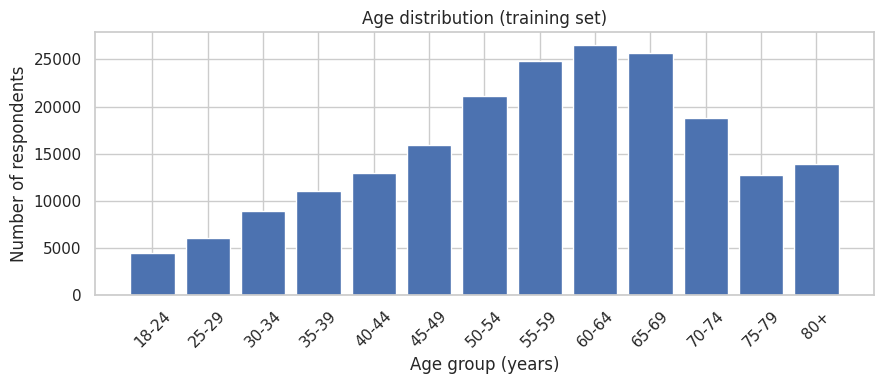

In [10]:
# Example: age-group distribution
age_counts = df["Age"].map(age_labels).value_counts().reindex(age_labels.values())

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(age_counts.index, age_counts.values, color="#4C72B0")
ax.set_title("Age distribution (training set)")
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Number of respondents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

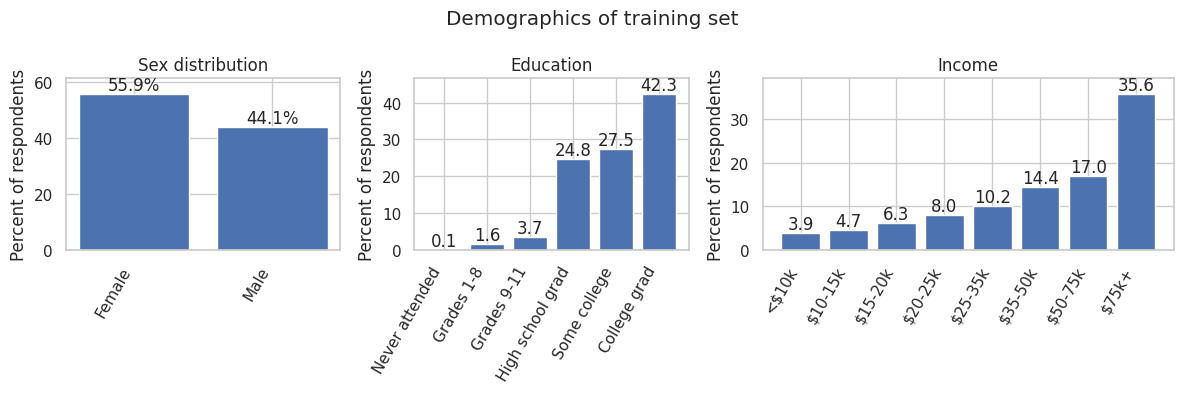

In [11]:
# Sex, education, and income distributions
sex_percent = df["Sex"].map({0: "Female", 1: "Male"}).value_counts(normalize=True).mul(100)
edu_percent = df["Education"].map(education_labels).value_counts(normalize=True).reindex(education_labels.values()).mul(100)
income_percent = df["Income"].map(income_labels).value_counts(normalize=True).reindex(income_labels.values()).mul(100)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1, 1.5]})

axes[0].bar(sex_percent.index, sex_percent.values, color="#4C72B0")
axes[0].set_title("Sex distribution")
axes[0].set_ylabel("Percent of respondents")

axes[1].bar(edu_percent.index, edu_percent.values, color="#4C72B0")
axes[1].set_title("Education")
axes[1].set_ylabel("Percent of respondents")

axes[2].bar(income_percent.index, income_percent.values, color="#4C72B0")
axes[2].set_title("Income")
axes[2].set_ylabel("Percent of respondents")

for ax, values in zip(axes, [sex_percent, edu_percent, income_percent]):
  for i, v in enumerate(values.values):
    if ax is axes[0]:
      ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom")
    else:
      ax.text(i, v, f"{v:.1f}", ha="center", va="bottom")
  ax.set_ylim(0, values.max() * 1.1)
  ax.tick_params(axis="x", rotation=60)
  plt.setp(ax.get_xticklabels(), ha = 'right')



fig.suptitle("Demographics of training set")
plt.tight_layout()
plt.show()

The sample is 55.9% female and 44.1% male. It skews toward older people as the most common group is age 60 to 64, with about 60% of respondents being 55 and above, 35% 65 and above, and less than 10% being under 35 years old. Respondents are also relatively well-educated as previously mentioned (69.8% have some amount of college education, 42.3% are college graduates) and higher income (35.6% report a household income of 75k+). Although, about 1/3 earn under 35k, so its not incredibly imbalanced. Because the sample is older, more educated, and wealthier than the general US adult population, results might not be able to generalize equally to younger and/or lower income groups, which we note as a real limitation of the dataset and models.

## Features vs. diabetes

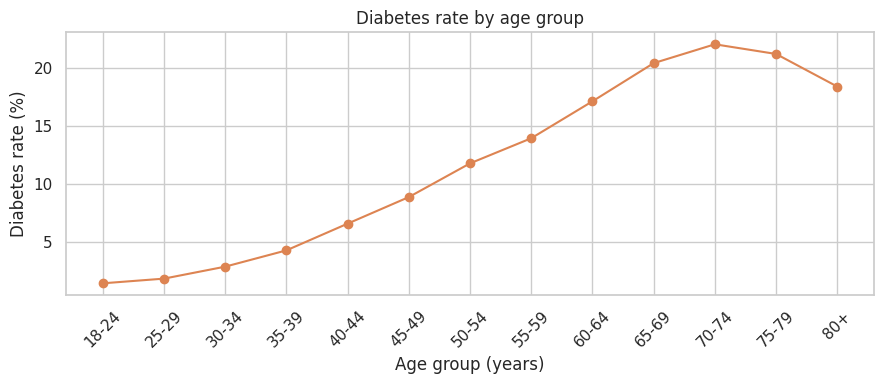

In [12]:
# Diabetes rate by age group
rate_by_age = df.groupby("Age")["Diabetes"].mean().mul(100).rename(index=age_labels)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(rate_by_age.index, rate_by_age.values, marker="o", color="#DD8452")
ax.set_title("Diabetes rate by age group")
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Diabetes rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

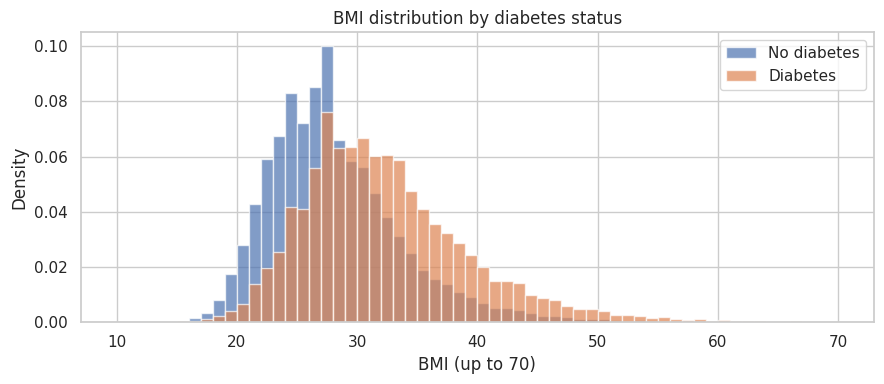

In [13]:
# BMI distribution by diabetes status

fig, ax = plt.subplots(figsize=(9, 4))
for status, color, label in [(0, '#4C72B0', 'No diabetes'), (1, '#DD8452', 'Diabetes')]:
    ax.hist(df.loc[df["Diabetes"] == status, "BMI"], bins=range(10,71), density=True, alpha=0.7, color=color, label=label)
ax.set_title("BMI distribution by diabetes status")
ax.set_xlabel("BMI (up to 70)")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()

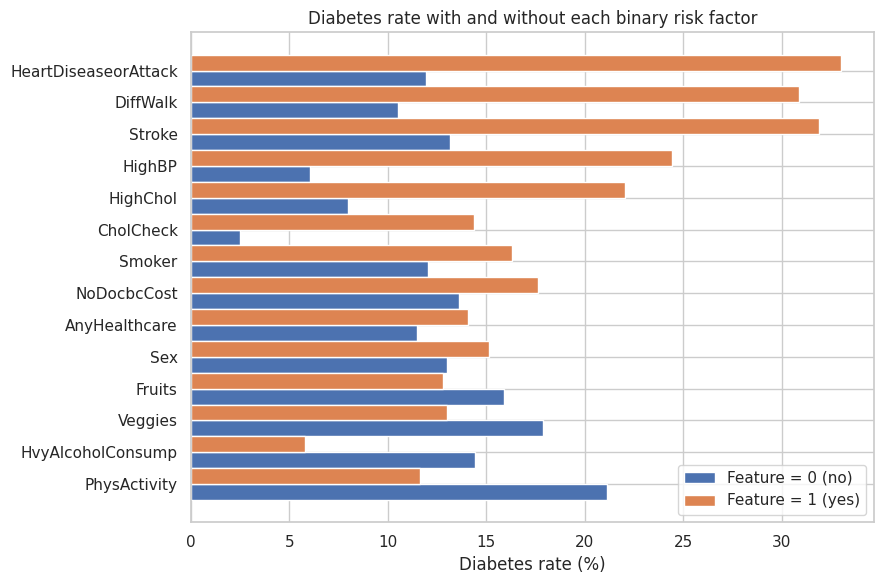

,No (0),Yes (1),Difference
HeartDiseaseorAttack,11.9,33.0,21.1
DiffWalk,10.5,30.9,20.4
Stroke,13.2,31.9,18.7
HighBP,6.0,24.5,18.4
HighChol,8.0,22.0,14.1
CholCheck,2.5,14.4,11.9
Smoker,12.0,16.3,4.3
NoDocbcCost,13.6,17.6,4.0
AnyHealthcare,11.5,14.1,2.6
Sex,13.0,15.1,2.2


In [14]:
# Diabetes rate with and without each binary risk factor

# note: for sex, male is 1, female is 0

rates = pd.DataFrame({"No (0)": [df.loc[df[c] == 0, "Diabetes"].mean() * 100 for c in binary],
                      "Yes (1)": [df.loc[df[c] == 1, "Diabetes"].mean() * 100 for c in binary]}, index = binary)
rates["Difference"] = rates["Yes (1)"] - rates["No (0)"]
rates = rates.sort_values("Difference")

fig, ax = plt.subplots(figsize=(9, 6))
y_pos = np.arange(len(binary))
ax.barh(y_pos - 0.25, rates["No (0)"], height = 0.5, color="#4C72B0", label="Feature = 0 (no)")
ax.barh(y_pos + 0.25, rates["Yes (1)"], height = 0.5, color="#DD8452", label="Feature = 1 (yes)")
ax.set_yticks(y_pos)
ax.set_yticklabels(rates.index)
ax.set_title("Diabetes rate with and without each binary risk factor")
ax.set_xlabel("Diabetes rate (%)")
ax.legend()
plt.tight_layout()
plt.show()

rates.round(1).sort_values("Difference", ascending = False)

NOTE: Sex: 1 = male, 0 = female

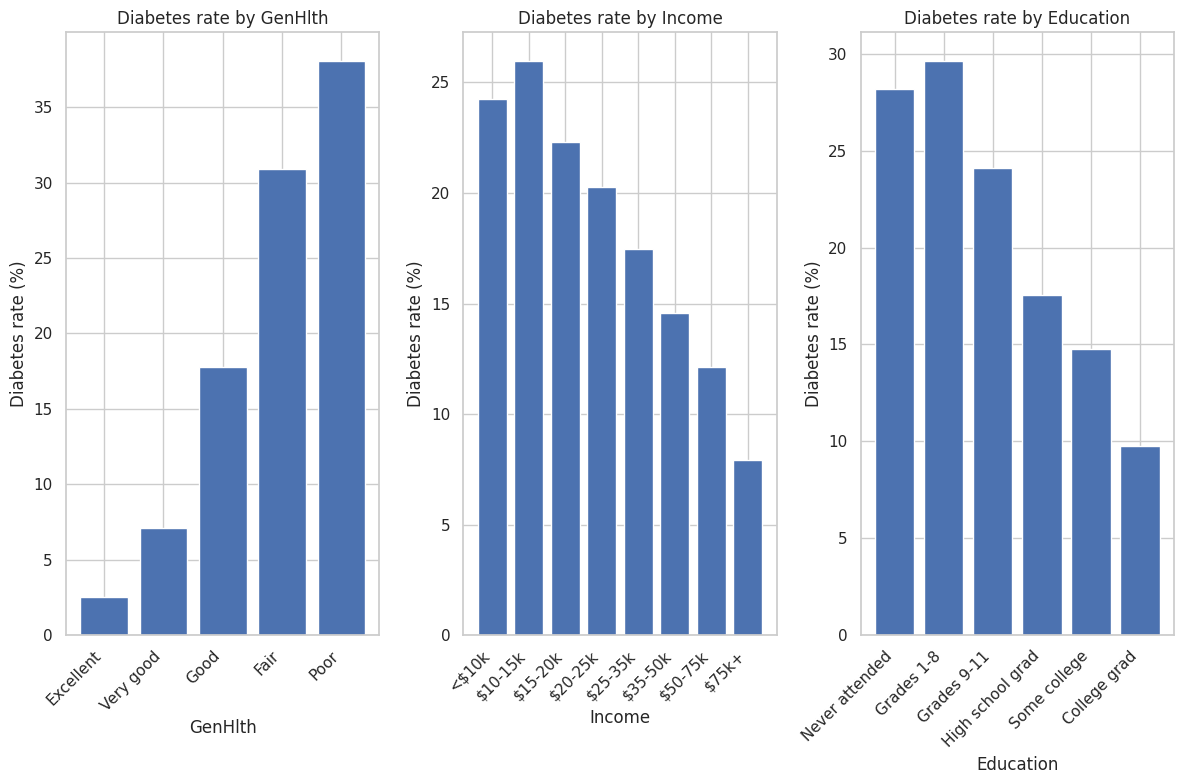

In [15]:
# Diabetes rate across the ordinal levels of variables
fig, axes = plt.subplots(1, 3, figsize=(12, 8))
for ax, (col, labels) in zip(axes, [("GenHlth", genhlth_labels), ("Income", income_labels), ("Education", education_labels)]):
    rate = df.groupby(col)["Diabetes"].mean().mul(100).rename(index = labels)
    ax.bar(rate.index, rate.values, color="#4C72B0")
    ax.set_title(f"Diabetes rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Diabetes rate (%)")
    ax.tick_params(axis = 'x', labelrotation = 45)
    plt.setp(ax.get_xticklabels(), ha = 'right')
plt.tight_layout()
plt.show()

Age: the diabetes rate rises steadily with age from 1.4% among young adults (18-24) to a peak of 22% at ages 70 to 74, before dropping slightly in the oldest age groups.

BMI: the respondents with diabetes have higher BMIs (median 31 vs median 27) and their distribution is shifted right slightly.

Binary risk factors: the largest differences are for heart disease or heart attack (33% vs 11.9% diabetes rate), difficulty walking (31% vs 10.5%), stroke (31.9% vs 13.2%), high blood pressure (24.5% vs 6%), and high cholesterol (22% vs 8%). Physical activity, fruit intake, and vegetable intake are also associated with lower diabetes rates. Heavy alcohol use is surprisingly also associated with a lower rate (5.8% vs 14.4%), which likely means there's some sort of confounding variable or reverse cause rather than a direct protective effect occurring (possible explanation that those with diabetes are more frequently advised by their doctors to drink less).

General health, income, and education: the diabetes rate climbs sharply as self-rated health worsens (2.5% for "excellent" vs 38.1% for "poor"), and falls as income goes up (26% at 10-15k vs 7.9% at 75k+), and education goes up (29.6% for grades 1 to 8 vs 9.7% for college graduates), which is consistent with known social determinants/assumptions of health.

These are just associations in observational survey data, not actual causal effects, but they do suggest that general health, high blood pressure, BMI, age, and cardiovascular conditions are likely going to be some of the strongest predictors/factors.

## Correlations

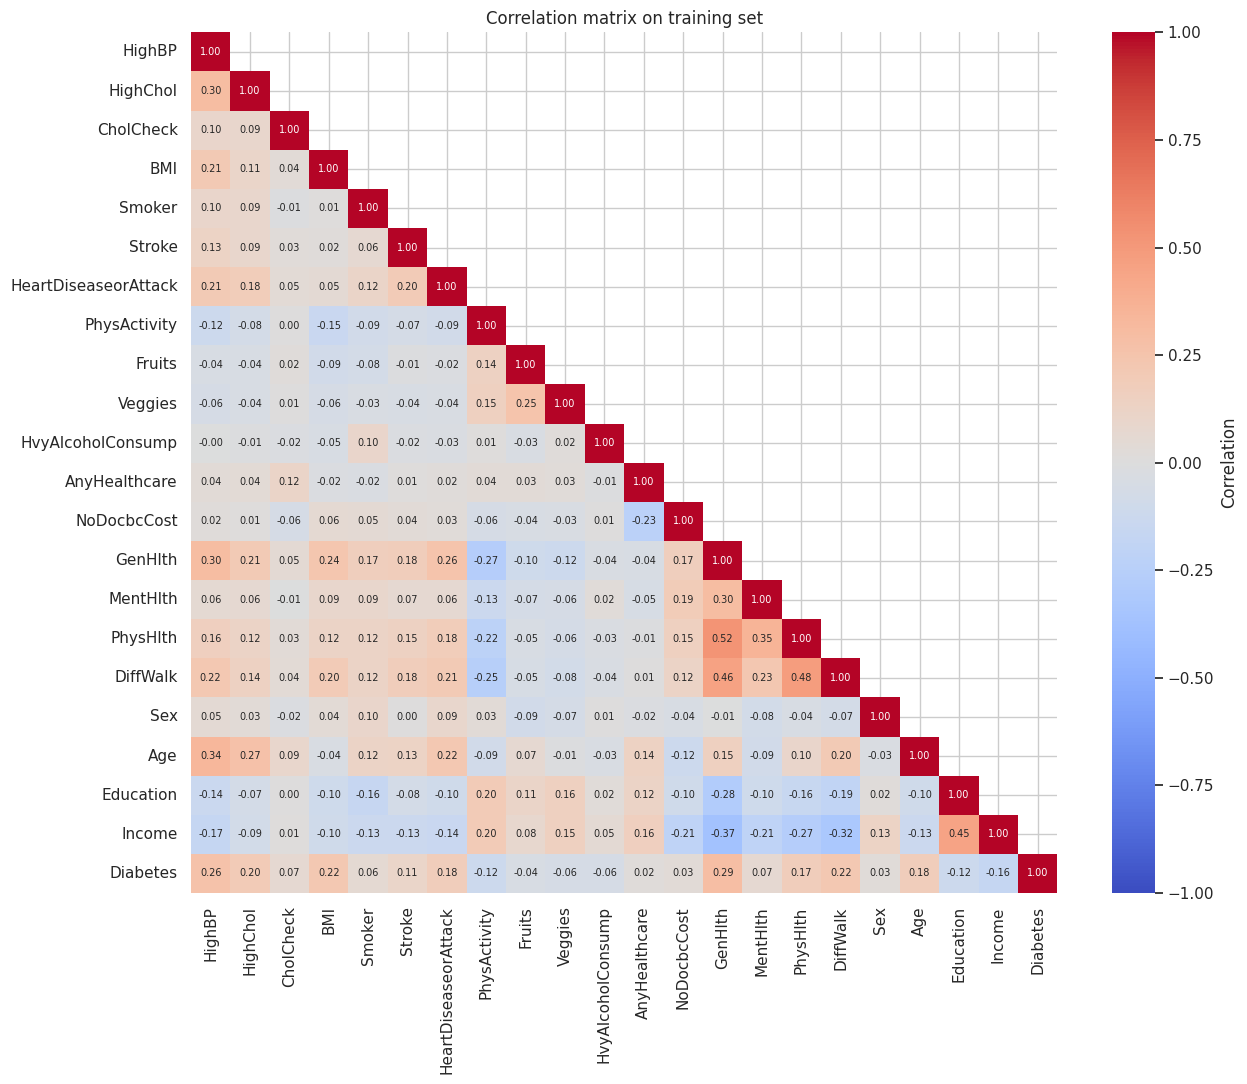

In [16]:
# Correlation matrix of all features and the target (Pearson coefficient)
corr = df.corr()

fig, ax = plt.subplots(figsize = (13, 11))
mask = np.triu(np.ones_like(corr, dtype = bool), k = 1)
sns.heatmap(corr, mask = mask, cmap = "coolwarm", vmin = -1, vmax = 1, center = 0, annot = True, fmt = ".2f", annot_kws = {"size": 7}, cbar_kws = {"label": "Correlation"}, ax = ax)
ax.set_title("Correlation matrix on training set")
plt.tight_layout()
plt.show()

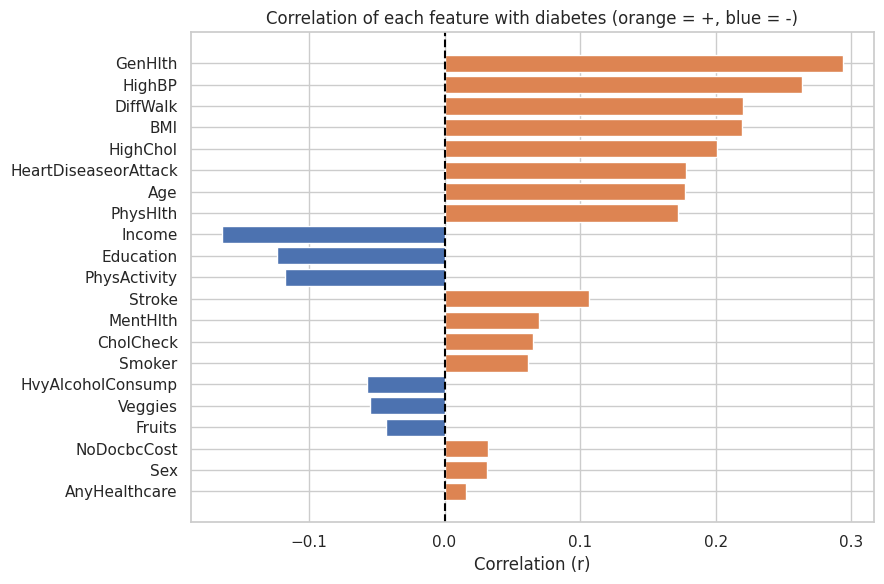

,Correlation with diabetes
GenHlth,0.294
HighBP,0.263
DiffWalk,0.220
BMI,0.219
HighChol,0.201
HeartDiseaseorAttack,0.178
Age,0.177
PhysHlth,0.172
Income,-0.164
Education,-0.124


In [17]:
# Correlation of each feature with diabetes, sorted by strength (r)

target_corr = corr["Diabetes"].drop("Diabetes").sort_values(key = abs)

fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#DD8452" if v > 0 else "#4C72B0" for v in target_corr]
ax.barh(target_corr.index, target_corr.values, color=colors)
ax.axvline(0, color="black", linestyle="--")
ax.set_title("Correlation of each feature with diabetes (orange = +, blue = -)")
ax.set_xlabel("Correlation (r)")
plt.tight_layout()
plt.show()

target_corr.sort_values(key = abs, ascending = False).round(3).to_frame("Correlation with diabetes")

Correlation with diabetes: the strongest correlations are with general health (r = 0.29, worse health leading to higher diabetes rate), high blood pressure (0.26), difficulty walking (0.22), BMI (0.22), high cholesterol (0.20), heart disease (0.18), age (0.18), and days of poor physical health (0.17). Income (r = -0.16), education (-0.12), and physical activity (-0.12) are negatively correlated with diabetes. Multiple features like healthcare coverage, sex, and cost barriers are barely correlated with diabetes at all with r values less than 0.04.

Overall strength: all correlations with diabetes are weak to moderate (r under 0.29 or so), so no single feature predicts diabetes on its own incredibly well, so models will need to combine many of these features for accurate predictions.

Correlations between features: the strongest are among the health status measures/metrics like general health with physical health days (0.52), physical health days with difficulty walking (0.48), and general health with difficulty walking (0.46). Education and income are also correlated (0.45), which makes sense to an extent. These overlaps/multicollinearity can make individual coefficients in linear models harder to interpret but they're not strong enough to cause any major issues directly.

Note: Pearson correlation only captures linear relationships and treats ordinal codes as evenly spaced so it may understate the true effects if they're non-linear that a tree-based model or neural networks will be able to pick up on.

## Summary of findings

Class imbalance: only 13.9% of the 202,944 training respondents have diabetes. Accuracy alone would therefore be misleading due to this major imbalance, so models should be compared with ROC-AUC, recall, precision, F1 score, and confusion matrices. They should also use stratified cross-validation and class weights to further account for this class imbalance.

Sample itself: respondents are 55.9% female and skew towards older (about 60% of the sample is 55 and above), more educated, and higher income people than the general US adult population, which could potentially limit how well the results generalize.

Strongest risk factors: poor self-rated general health, high blood pressure, high BMI, difficulty walking, high cholesterol, heart disease, older age, and more days of poor physical health are all very clearly associated with higher diabetes rates, making them very strong risk factors. On the other hand, physical activity, higher income, and higher education are associated with lower rates, possibly making them protective factors.

No one strong predictor: every feature's correlation with diabetes is weak to moderate (r of 0.29 or less), so accurate predictions will depend on combining these many weaker/moderate features rather than any singular strong one. Non-linear patterns like the age curve may favor tree-based models or neural networks, which is a caveat of the feature correlations as we used Pearson.

Data notes: there aren't any missing values, but BMI and health days are self-reported and some extreme BMI values may be errors (some values go above 90). Several features like health coverage and cholesterol checks don't vary much and likely will provide little to no additional information compared to other features available in this dataset. All the found patterns are also just associations, not actual causal effects.